In [1]:
import pandas as pd
import numpy as np


import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split


from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)


from sklearn.compose import ColumnTransformer


from sklearn.pipeline import Pipeline


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)


from sklearn.tree import DecisionTreeRegressor


from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)


from xgboost import XGBRegressor


import joblib

In [2]:
DATA_PATH = (
    "../datasets/final_disaster_dataset_engineered.csv"
)


df = pd.read_csv(
    DATA_PATH
)


print(
    df.shape
)


df.head()

(2374, 25)


,SourceEventID,DisasterType,Latitude,Longitude,Magnitude,Depth,Time,Temperature,Humidity,Rainfall,...,NearestHospitalDistanceKm,HospitalCount25Km,NearestClinicDistanceKm,ClinicCount25Km,NearestSchoolDistanceKm,SchoolCount25Km,NearestFireStationDistanceKm,FireStationCount25Km,WeatherScore,InfrastructureScore
0,18,Earthquake,27.5051,92.1524,4.3,10.000,2026-06-21 00:53:20.927000,0.526455,0.831579,0.0,...,0.940875,0.000000,0.854388,0.000000,0.966349,0.000849,0.646845,0.000000,0.452678,0.426163
1,19,Earthquake,27.4598,92.0424,4.3,10.000,2026-06-21 00:52:54.610000,0.584656,0.915789,0.0,...,0.955199,0.000000,0.863531,0.000000,0.954999,0.000000,0.650855,0.000000,0.500149,0.428073
2,22,Earthquake,24.3478,94.0847,4.5,52.125,2026-06-18 15:29:24.907000,0.718254,0.915789,0.0,...,0.979486,0.005413,0.964291,0.003571,0.984801,0.007640,0.883867,0.000000,0.544681,0.478634
3,39,Earthquake,24.9682,93.0641,4.4,48.154,2026-06-11 15:40:35.593000,0.805556,0.863158,0.0,...,0.981666,0.012179,0.985625,0.005357,0.971148,0.020374,0.953640,0.025641,0.556238,0.494454
4,46,Earthquake,32.3888,76.6062,4.9,10.000,2026-06-05 16:34:36.131000,0.395503,0.978947,0.0,...,0.982899,0.004060,0.939849,0.000000,0.983533,0.007640,0.923348,0.000000,0.458150,0.480166


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2374 entries, 0 to 2373
Data columns (total 25 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   SourceEventID                 2374 non-null   int64  
 1   DisasterType                  2374 non-null   object 
 2   Latitude                      2374 non-null   float64
 3   Longitude                     2374 non-null   float64
 4   Magnitude                     2374 non-null   float64
 5   Depth                         2374 non-null   float64
 6   Time                          2374 non-null   object 
 7   Temperature                   2374 non-null   float64
 8   Humidity                      2374 non-null   float64
 9   Rainfall                      2374 non-null   float64
 10  WindSpeed                     2374 non-null   float64
 11  Population                    2374 non-null   float64
 12  PopulationDensity             2374 non-null   float64
 13  Sev

In [4]:
df.describe()

,SourceEventID,Latitude,Longitude,Magnitude,Depth,Temperature,Humidity,Rainfall,WindSpeed,Population,...,NearestHospitalDistanceKm,HospitalCount25Km,NearestClinicDistanceKm,ClinicCount25Km,NearestSchoolDistanceKm,SchoolCount25Km,NearestFireStationDistanceKm,FireStationCount25Km,WeatherScore,InfrastructureScore
count,2374.000000,2374.000000,2374.000000,2374.000000,2374.000000,2374.000000,2374.000000,2374.000000,2374.000000,2.374000e+03,...,2.374000e+03,2374.000000,2374.000000,2374.000000,2374.000000,2374.000000,2374.000000,2374.000000,2374.000000,2.374000e+03
mean,10409.872789,22.680250,86.458769,4.410046,30.649539,0.688092,0.708505,0.015449,9.409230,3.027321e+05,...,8.728121e-01,0.008614,0.822375,0.006740,0.861597,0.004292,0.788045,0.005325,0.470682,4.212249e-01
std,5507.507980,8.646846,8.856882,0.452307,20.382943,0.163363,0.223463,0.054202,8.048598,1.265608e+06,...,2.228408e-01,0.044740,0.219806,0.044112,0.220761,0.038472,0.194056,0.042243,0.098090,1.079474e-01
min,18.000000,6.757000,68.963000,3.500000,3.300000,0.000000,0.000000,0.000000,0.000000,3.639640e-01,...,-2.220446e-16,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.113478,-2.775558e-17
25%,5436.250000,13.483250,76.761250,4.100000,10.000000,0.615741,0.621053,0.000000,3.600000,1.672029e+03,...,9.162385e-01,0.000000,0.784815,0.000000,0.888373,0.000000,0.757040,0.000000,0.415031,4.274291e-01
50%,11242.500000,24.504100,92.456000,4.400000,30.000000,0.753307,0.757895,0.000000,6.400000,2.255398e+04,...,9.531612e-01,0.000000,0.906631,0.000000,0.940860,0.000000,0.852107,0.000000,0.498545,4.523082e-01
75%,15312.750000,29.093700,93.221000,4.600000,38.500000,0.801587,0.863158,0.008197,13.000000,2.519583e+05,...,9.767047e-01,0.005413,0.961364,0.001786,0.970290,0.001698,0.908785,0.000000,0.539998,4.731843e-01
max,18675.000000,35.479000,97.352100,7.700000,131.400000,1.000000,1.000000,1.000000,50.700000,2.649584e+07,...,1.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.913232,9.923442e-01


In [5]:
df.isnull().sum()

SourceEventID                   0
DisasterType                    0
Latitude                        0
Longitude                       0
Magnitude                       0
Depth                           0
Time                            0
Temperature                     0
Humidity                        0
Rainfall                        0
WindSpeed                       0
Population                      0
PopulationDensity               0
Severity                        0
ImpactScore                     0
NearestHospitalDistanceKm       0
HospitalCount25Km               0
NearestClinicDistanceKm         0
ClinicCount25Km                 0
NearestSchoolDistanceKm         0
SchoolCount25Km                 0
NearestFireStationDistanceKm    0
FireStationCount25Km            0
WeatherScore                    0
InfrastructureScore             0
dtype: int64

In [6]:
df = df.drop(

    columns=[

        "SourceEventID",

        "Time"

    ]

)

In [7]:
FEATURE_COLUMNS = [

    #"DisasterType",

    "Magnitude",

    #"Depth",

    "WeatherScore",

    "WindSpeed",

    "PopulationDensity",

    "InfrastructureScore"

]

TARGET_COLUMN = "ImpactScore"

X = df[FEATURE_COLUMNS]

y = df[TARGET_COLUMN]

In [8]:
numeric_features = [
    "Magnitude",
    #"Depth",
    "WeatherScore",
    "WindSpeed",
    "PopulationDensity",
    "InfrastructureScore"
]

categorical_features = [
#"DisasterType"
]

In [9]:
preprocessor = ColumnTransformer(

    transformers=[


        (

            "num",

            StandardScaler(),

            numeric_features

        ),


        (

            "cat",

            OneHotEncoder(

                handle_unknown="ignore"

            ),

            categorical_features

        )

    ]

)

In [10]:
X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.2,

    random_state=42,

    shuffle=True

)


print(
    X_train.shape,
    X_test.shape
)

(1899, 5) (475, 5)


In [11]:
models = {


    "Linear Regression":

    LinearRegression(),


    "Ridge Regression":

    Ridge(),


    "Lasso Regression":

    Lasso(),


    "Decision Tree":

    DecisionTreeRegressor(

        random_state=42

    ),


    "Random Forest":

    RandomForestRegressor(

        n_estimators=200,

        random_state=42

    ),


    "Gradient Boosting":

    GradientBoostingRegressor(

        random_state=42

    ),


    "Extra Trees":

    ExtraTreesRegressor(

        n_estimators=200,

        random_state=42

    ),


    "XGBoost":

    XGBRegressor(

    n_estimators=300,

    learning_rate=0.05,

    max_depth=5,

    objective="reg:squarederror",

    random_state=42,

    n_jobs=-1

)

}

In [12]:
results = []


trained_models = {}


for name, model in models.items():


    pipeline = Pipeline(

        steps=[


            (

                "preprocessing",

                preprocessor

            ),


            (

                "model",

                model

            )

        ]

    )


    pipeline.fit(

        X_train,

        y_train

    )


    predictions = pipeline.predict(

        X_test

    )


    mae = mean_absolute_error(

        y_test,

        predictions

    )


    rmse = np.sqrt(

        mean_squared_error(

            y_test,

            predictions

        )

    )


    r2 = r2_score(

        y_test,

        predictions

    )


    results.append(

        [

            name,

            mae,

            rmse,

            r2

        ]

    )


    trained_models[name] = pipeline

In [13]:
results_df = pd.DataFrame(

    results,

    columns=[

        "Model",

        "MAE",

        "RMSE",

        "R2 Score"

    ]

)


results_df.sort_values(

    by="R2 Score",

    ascending=False

)

,Model,MAE,RMSE,R2 Score
7,XGBoost,0.349578,0.532012,0.994727
5,Gradient Boosting,0.406425,0.538678,0.994594
6,Extra Trees,0.478285,0.757002,0.989324
4,Random Forest,0.517648,0.778104,0.988721
3,Decision Tree,0.890982,1.322616,0.967411
0,Linear Regression,4.503935,5.246798,0.487144
1,Ridge Regression,4.503815,5.246884,0.487127
2,Lasso Regression,4.733630,5.636307,0.408171


In [14]:
experiment_results = results_df.copy()

In [15]:
experiment_results.to_csv(

    "experiment_results.csv",

    index=False

)


print(
    "Experiment  results saved"
)

Experiment  results saved


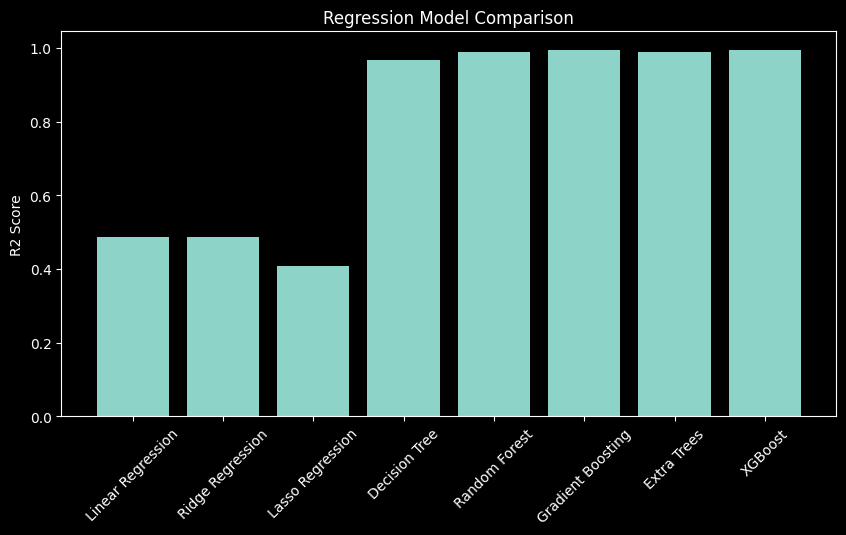

In [16]:
plt.figure(
    figsize=(10,5)
)


plt.bar(

    results_df["Model"],

    results_df["R2 Score"]

)


plt.xticks(

    rotation=45

)


plt.ylabel(
    "R2 Score"
)


plt.title(
    "Regression Model Comparison"
)


plt.show()

In [17]:
best_model_name = results_df.sort_values(

    "R2 Score",

    ascending=False

).iloc[0]["Model"]

best_model = trained_models[best_model_name]

print(best_model_name)

joblib.dump(

    best_model,

    "impact_prediction_model.pkl"

)

XGBoost


['impact_prediction_model.pkl']

In [18]:
if hasattr(
    best_model.named_steps["model"],
    "feature_importances_"
):

    feature_names = (
        best_model
        .named_steps["preprocessing"]
        .get_feature_names_out()
    )

    importance_df = pd.DataFrame(
        {
            "Feature": feature_names,
            "Importance": best_model.named_steps["model"].feature_importances_
        }
    )

    importance_df = importance_df.sort_values(
        "Importance",
        ascending=False
    )

    display(importance_df)

else:

    print("Feature importance not available.")

,Feature,Importance
3,num__PopulationDensity,0.605699
0,num__Magnitude,0.346287
2,num__WindSpeed,0.043692
1,num__WeatherScore,0.002449
4,num__InfrastructureScore,0.001873
